# 02 Feature analysis
Point-in-time features from `data/processed/features.parquet` (built by `scripts/train.py` / `build_features.py`). Splits are chronological.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (8, 3.5), "axes.grid": True, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 140)
from identitygraph.config import PROCESSED_DIR
from identitygraph.features.pipeline import BASE_FEATURES, GRAPH_FEATURES
f = pd.read_parquet(PROCESSED_DIR / 'features.parquet')
print(f.shape); f['split'].value_counts()

(20000, 46)


split
train    12000
val       4000
test      4000
Name: count, dtype: int64

## Univariate signal (train period only)
Mean of each feature for fraud vs legitimate, and AUC of the raw feature as a score (train split only, so no test leakage).

In [2]:
from sklearn.metrics import roc_auc_score
tr = f[f.split == 'train']
rows = []
for c in BASE_FEATURES + GRAPH_FEATURES:
    rows.append((c, tr[c].mean(), tr.loc[tr.fraud_label == 1, c].mean(), tr.loc[tr.fraud_label == 0, c].mean(), roc_auc_score(tr.fraud_label, tr[c])))
t = pd.DataFrame(rows, columns=['feature', 'mean', 'mean_fraud', 'mean_legit', 'auc']).set_index('feature')
t['auc_strength'] = (t.auc - .5).abs()
t.sort_values('auc_strength', ascending=False).head(15).round(3)

,mean,mean_fraud,mean_legit,auc,auc_strength
feature,,,,,
component_size,1.146,2.265,1.070,0.716,0.216
component_distinct_applicants,1.146,2.265,1.070,0.716,0.216
max_entity_degree,0.140,1.198,0.068,0.716,0.216
device_id_prior_distinct_applicants,0.051,0.610,0.013,0.610,0.110
device_id_prior_apps,0.051,0.610,0.013,0.610,0.110
ip_address_prior_apps,0.056,0.679,0.013,0.609,0.109
ip_address_prior_distinct_applicants,0.056,0.679,0.013,0.609,0.109
ip_address_apps_7d,0.040,0.617,0.001,0.606,0.106
device_id_apps_7d,0.031,0.471,0.001,0.606,0.106


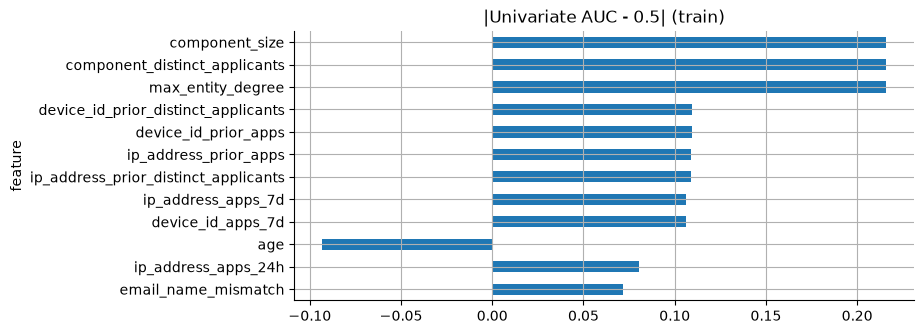

In [3]:
top = t.sort_values('auc_strength', ascending=False).head(12)
(top['auc'] - .5).plot.barh(title='|Univariate AUC - 0.5| (train)').invert_yaxis();

## Graph features
`component_size` and `neighbor_fraud_ratio` are computed chronologically (union-find); labels are only used when matured (>= 30 days) and from the train period.

                    mean   size
component_size                 
(0.0, 1.0]      0.036617  11115
(1.0, 2.0]      0.241228    456
(2.0, 4.0]      0.481013    316
(4.0, 8.0]      0.851852    108
(8.0, 16.0]     1.000000      5


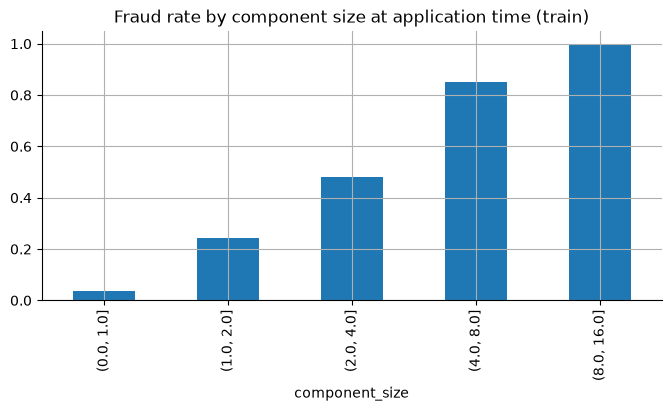

In [4]:
g = tr.groupby(pd.cut(tr.component_size, [0, 1, 2, 4, 8, 16, 1e9]), observed=True)['fraud_label'].agg(['mean', 'size'])
print(g)
g['mean'].plot.bar(title='Fraud rate by component size at application time (train)');

In [5]:
print('Test-period neighbor_fraud_ratio > 0:', (f[f.split == 'test'].neighbor_fraud_ratio > 0).mean().round(3))
print('Val  -period neighbor_fraud_ratio > 0:', (f[f.split == 'val'].neighbor_fraud_ratio > 0).mean().round(3))

Test-period neighbor_fraud_ratio > 0: 0.0
Val  -period neighbor_fraud_ratio > 0: 0.001


Leakage protections are asserted in `tests/unit/test_data_and_features.py` (point-in-time, future labels do not change features).